
# Task 1: Image Restoration and Segmentation

## Objective
To study image restoration and segmentation techniques by adding noise to an original photograph, applying filtering methods, evaluating image quality, and segmenting image regions using thresholding, morphological operations, edge detection, and watershed segmentation.

## Methods
1. Addition of Gaussian noise
2. Addition of salt-and-pepper noise
3. Image restoration using Gaussian and median filters
4. Image quality evaluation using PSNR and SSIM
5. Image thresholding and Otsu thresholding
6. Morphological operations: erosion, dilation, opening, and closing
7. Canny edge detection
8. Watershed segmentation


In [1]:
%pip install opencv-python numpy matplotlib scikit-image ultralytics

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install --upgrade --force-reinstall numpy==1.26.4 scikit-image==0.24.0

Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-1.26.4-cp311-cp311-win_amd64.whl.metadata (61 kB)
  Using cached scikit_image-0.24.0-cp311-cp311-win_amd64.whl.metadata (14 kB)
  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached pillow-13.0.0-cp311-cp311-win_amd64.whl.metadata (9.3 kB)
  Using cached imageio-2.38.1-py3-none-any.whl.metadata (9.7 kB)
  Using cached tifffile-2026.3.3-py3-none-any.whl.metadata (31 kB)
  Using cached packaging-26.3-py3-none-any.whl.metadata (3.5 kB)
  Using cached lazy_loader-0.6-py3-none-any.whl.metadata (6.0 kB)
Using cached numpy-1.26.4-cp311-cp311-win_amd64.whl (15.8 MB)
Using cached scikit_image-0.24.0-cp311-cp311-win_amd64.whl (12.8 MB)
Using cached imageio-2.38.1-py3-none-any.whl (328 kB)
Using cached lazy_loader-0.6-py3-none-any.whl (8.8 kB)
Using cached networkx-3.6.1-py3-none-any.whl (2.1 MB)
Using c

  You can safely remove it manually.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  You can safely remove it manually.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.0 requires FuzzyTM>=0.4.0, which is not installed.
streamlit 1.30.0 requires packaging<24,>=16.8, but you have packaging 26.3 which is incompatible.
streamlit 1.30.0 requires pillow<11,>=7.1.0, but you have pillow 13.0.0 which is incompatible.


In [3]:
%pip install opencv-python==4.10.0.84

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [4]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import skimage

from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

print("All libraries imported successfully!")
print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("scikit-image:", skimage.__version__)

All libraries imported successfully!
NumPy: 1.26.4
OpenCV: 4.10.0
scikit-image: 0.24.0


Image loaded successfully!
Image dimensions: (1280, 1130, 3)


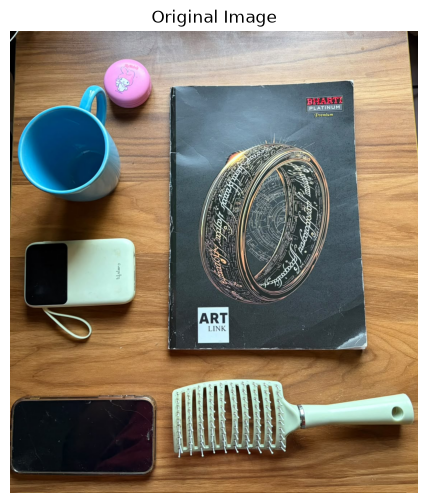

In [5]:
image = cv2.imread("dataset/original.jpg")

if image is None:
    print("Image not found. Check the file path and filename.")
else:
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    print("Image loaded successfully!")
    print("Image dimensions:", image.shape)

    plt.figure(figsize=(8, 6))
    plt.imshow(image)
    plt.title("Original Image")
    plt.axis("off")
    plt.show()

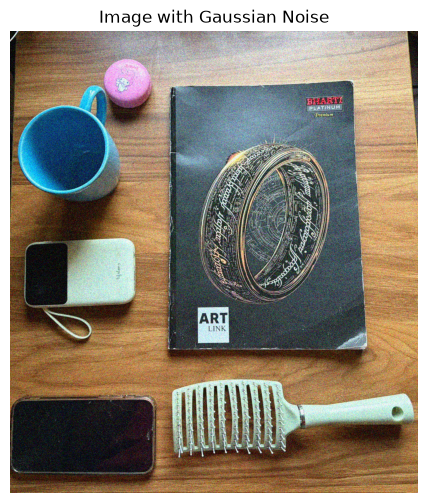

Gaussian noise image saved!


In [6]:
# Convert image to float values between 0 and 1
image_float = image.astype(np.float32) / 255.0

# Set random seed for repeatable results
np.random.seed(42)

# Generate Gaussian noise
mean = 0
standard_deviation = 0.12

gaussian_noise = np.random.normal(
    mean,
    standard_deviation,
    image_float.shape
).astype(np.float32)

# Add noise and keep values in the valid range
noisy_gaussian = np.clip(
    image_float + gaussian_noise, 0, 1
)

# Convert back to 8-bit image
noisy_gaussian = (noisy_gaussian * 255).astype(np.uint8)

# Display the result
plt.figure(figsize=(8, 6))
plt.imshow(noisy_gaussian)
plt.title("Image with Gaussian Noise")
plt.axis("off")
plt.show()

# Save the result
plt.imsave("outputs/gaussian_noisy.png", noisy_gaussian)

print("Gaussian noise image saved!")

In [7]:
import os

os.makedirs("outputs", exist_ok=True)

print("Outputs folder is ready!")
print("Current folder:", os.getcwd())

Outputs folder is ready!
Current folder: C:\Users\bangt\CCA3_Computer_Vision


In [8]:
plt.imsave("outputs/gaussian_noisy.png", noisy_gaussian)

print("Gaussian noise image saved successfully!")

Gaussian noise image saved successfully!


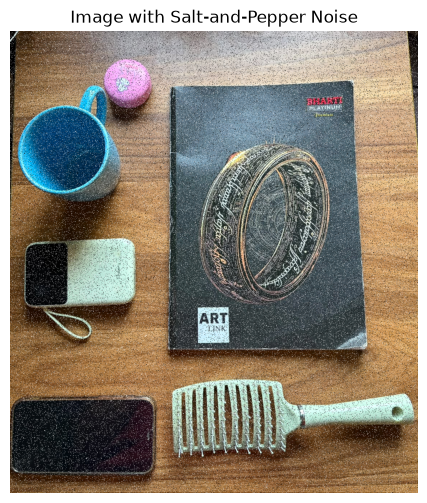

Black pixels: 73360
White pixels: 72323
Salt-and-pepper image saved!


In [9]:
# Start with a fresh copy of the original image
noisy_sp = image.copy()

height, width = image.shape[:2]
total_pixels = height * width

# Affect 10% of pixel locations
noise_fraction = 0.10
num_noise_pixels = int(total_pixels * noise_fraction)

np.random.seed(42)

# Select unique random pixel locations
indices = np.random.choice(
    total_pixels,
    num_noise_pixels,
    replace=False
)

rows, cols = np.unravel_index(indices, (height, width))

# Half of selected pixels become black
half = num_noise_pixels // 2
noisy_sp[rows[:half], cols[:half]] = [0, 0, 0]

# Remaining selected pixels become white
noisy_sp[rows[half:], cols[half:]] = [255, 255, 255]

# Display the result
plt.figure(figsize=(8, 6))
plt.imshow(noisy_sp)
plt.title("Image with Salt-and-Pepper Noise")
plt.axis("off")
plt.show()

# Save the result
plt.imsave("outputs/salt_pepper_noisy.png", noisy_sp)

# Verify black and white pixels
black_count = np.sum(np.all(noisy_sp == [0, 0, 0], axis=2))
white_count = np.sum(np.all(noisy_sp == [255, 255, 255], axis=2))

print("Black pixels:", black_count)
print("White pixels:", white_count)
print("Salt-and-pepper image saved!")

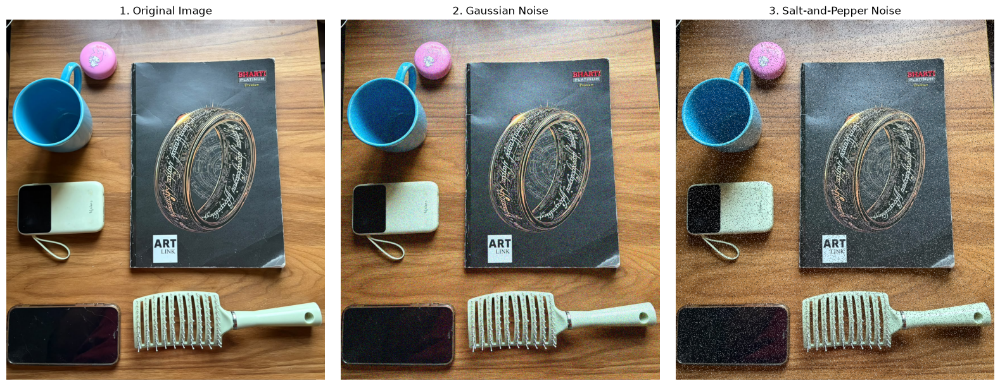

All three images compared and saved!


In [10]:
plt.figure(figsize=(16, 6))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("1. Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(noisy_gaussian)
plt.title("2. Gaussian Noise")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(noisy_sp)
plt.title("3. Salt-and-Pepper Noise")
plt.axis("off")

plt.tight_layout()

# Save the comparison figure
plt.savefig(
    "outputs/noise_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("All three images compared and saved!")

In [11]:
os.makedirs("outputs", exist_ok=True)

plt.imsave("outputs/salt_pepper_noisy.png", noisy_sp)
plt.savefig("outputs/noise_comparison.png", dpi=200, bbox_inches="tight")

print("All images saved successfully!")

All images saved successfully!


<Figure size 640x480 with 0 Axes>

In [12]:
# 1. Remove Gaussian noise using Gaussian Blur
gaussian_filtered = cv2.GaussianBlur(
    noisy_gaussian, (5, 5), 0
)

# 2. Remove salt-and-pepper noise using Median Filter
median_filtered = cv2.medianBlur(
    noisy_sp, 5
)

print("Noise reduction completed!")

Noise reduction completed!


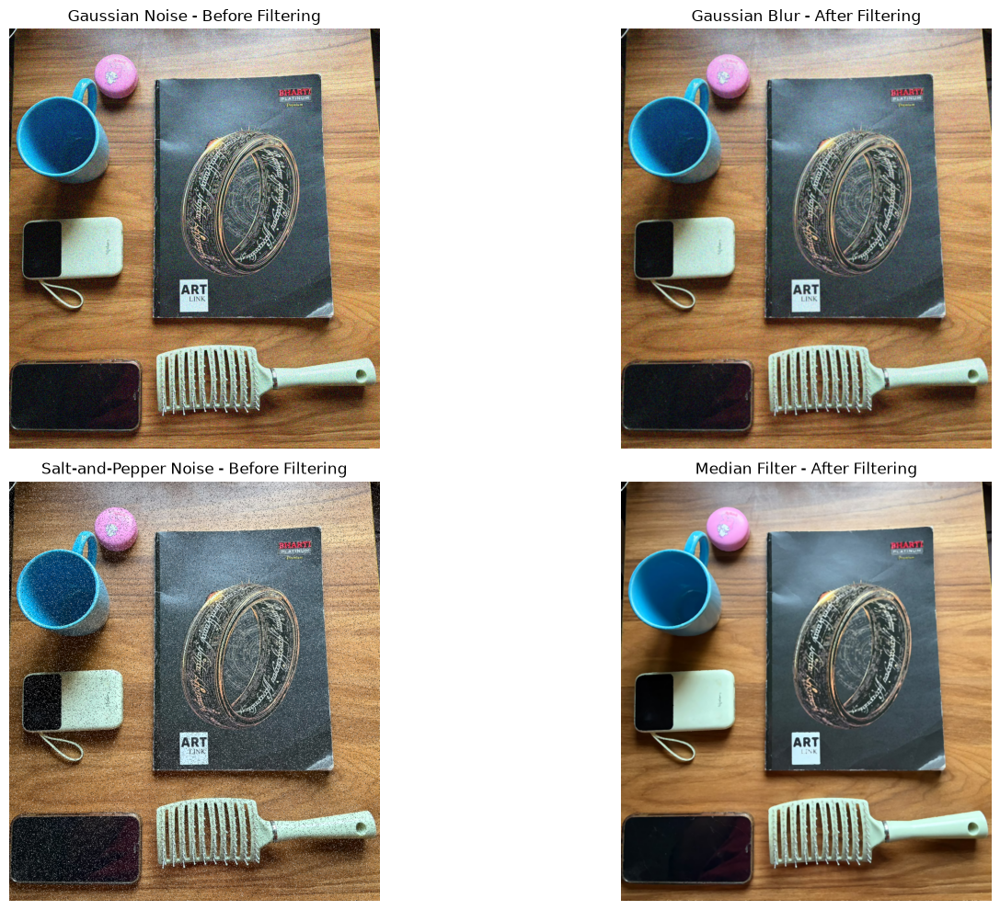

In [13]:
plt.figure(figsize=(16, 10))

plt.subplot(2, 2, 1)
plt.imshow(noisy_gaussian)
plt.title("Gaussian Noise - Before Filtering")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(gaussian_filtered)
plt.title("Gaussian Blur - After Filtering")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(noisy_sp)
plt.title("Salt-and-Pepper Noise - Before Filtering")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(median_filtered)
plt.title("Median Filter - After Filtering")
plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
# Calculate PSNR
psnr_gaussian = peak_signal_noise_ratio(
    image, gaussian_filtered, data_range=255
)

psnr_median = peak_signal_noise_ratio(
    image, median_filtered, data_range=255
)

# Calculate SSIM
ssim_gaussian = structural_similarity(
    image, gaussian_filtered,
    channel_axis=2, data_range=255
)

ssim_median = structural_similarity(
    image, median_filtered,
    channel_axis=2, data_range=255
)

print("Gaussian Blur Results")
print("PSNR:", round(psnr_gaussian, 2), "dB")
print("SSIM:", round(ssim_gaussian, 4))

print("\nMedian Filter Results")
print("PSNR:", round(psnr_median, 2), "dB")
print("SSIM:", round(ssim_median, 4))

Gaussian Blur Results
PSNR: 25.12 dB
SSIM: 0.6045

Median Filter Results
PSNR: 24.6 dB
SSIM: 0.7068


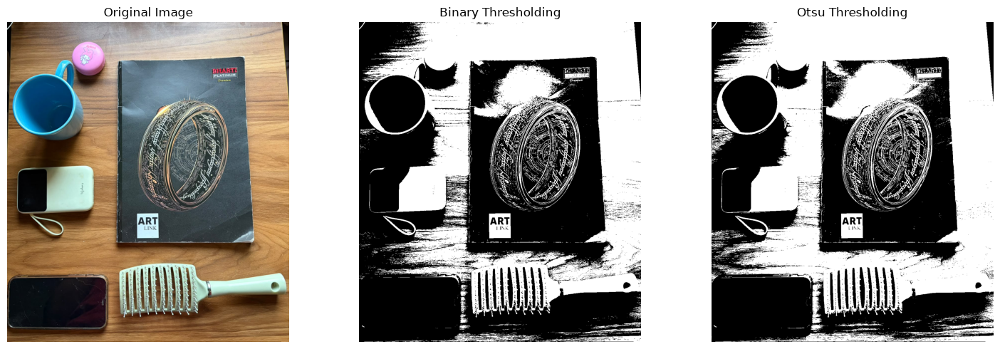

True

In [15]:
# Convert original RGB image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Apply binary thresholding
_, binary_threshold = cv2.threshold(
    gray, 127, 255, cv2.THRESH_BINARY
)

# Apply Otsu's thresholding
_, otsu_threshold = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binary_threshold, cmap="gray")
plt.title("Binary Thresholding")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(otsu_threshold, cmap="gray")
plt.title("Otsu Thresholding")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save results
os.makedirs("outputs", exist_ok=True)
cv2.imwrite("outputs/binary_threshold.png", binary_threshold)
cv2.imwrite("outputs/otsu_threshold.png", otsu_threshold)

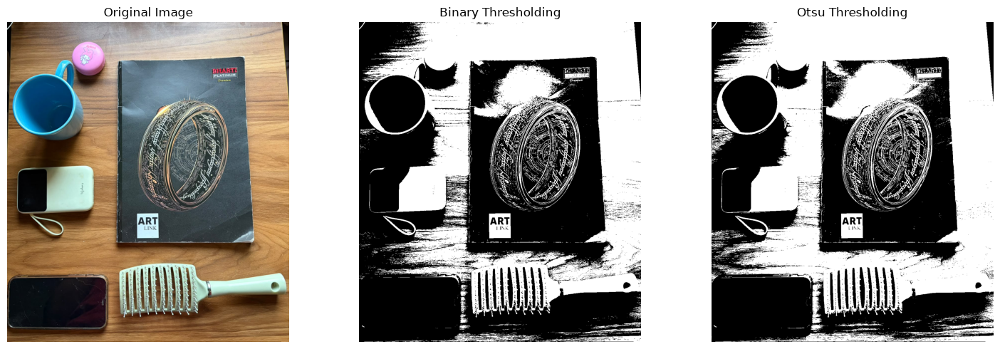

True

In [16]:
# Convert original RGB image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Apply binary thresholding
_, binary_threshold = cv2.threshold(
    gray, 127, 255, cv2.THRESH_BINARY
)

# Apply Otsu's thresholding
_, otsu_threshold = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binary_threshold, cmap="gray")
plt.title("Binary Thresholding")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(otsu_threshold, cmap="gray")
plt.title("Otsu Thresholding")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save results
os.makedirs("outputs", exist_ok=True)
cv2.imwrite("outputs/binary_threshold.png", binary_threshold)
cv2.imwrite("outputs/otsu_threshold.png", otsu_threshold)

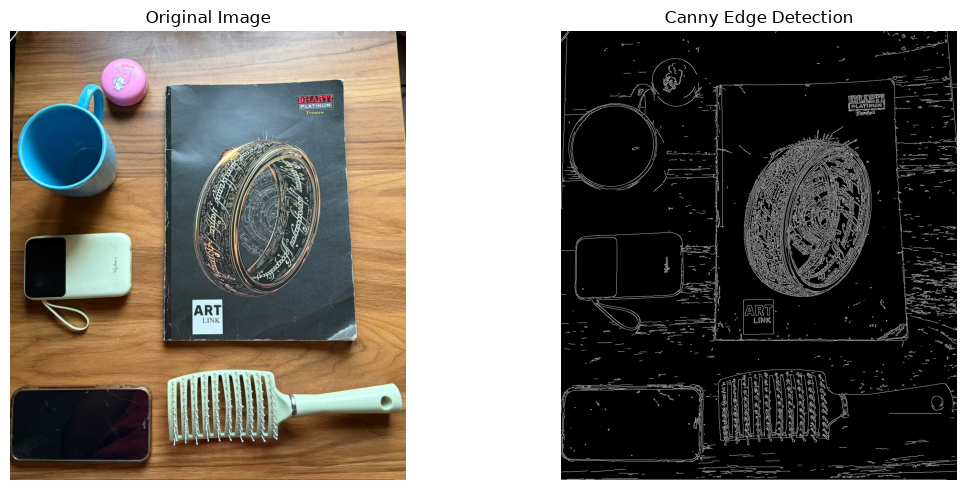

Canny edge image saved!


In [17]:
# Apply Canny edge detection to grayscale image
edges = cv2.Canny(gray, 100, 200)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite("outputs/canny_edges.png", edges)
print("Canny edge image saved!")

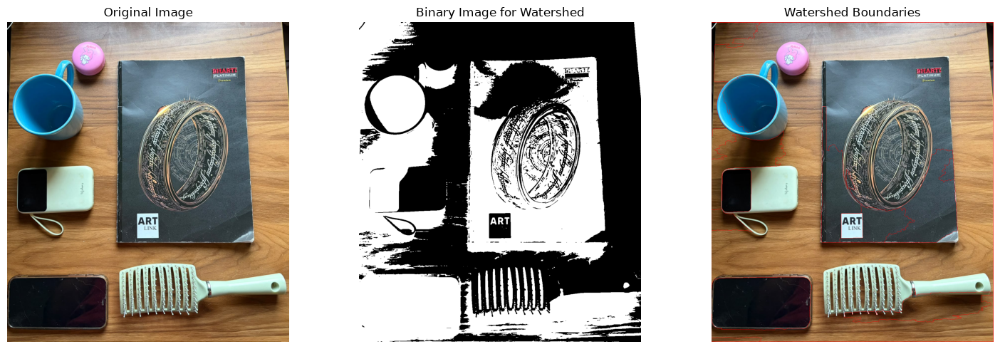

Watershed result saved!


In [18]:
# Smooth the original image
blurred = cv2.GaussianBlur(image, (5, 5), 0)

# Convert to grayscale and create a binary image
gray_blurred = cv2.cvtColor(blurred, cv2.COLOR_RGB2GRAY)
_, thresh = cv2.threshold(
    gray_blurred, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Remove small noise
kernel = np.ones((3, 3), np.uint8)
opening_ws = cv2.morphologyEx(
    thresh, cv2.MORPH_OPEN, kernel, iterations=2
)

# Find sure background
sure_bg = cv2.dilate(opening_ws, kernel, iterations=3)

# Find sure foreground
dist_transform = cv2.distanceTransform(
    opening_ws, cv2.DIST_L2, 5
)

_, sure_fg = cv2.threshold(
    dist_transform,
    0.4 * dist_transform.max(),
    255,
    0
)

sure_fg = np.uint8(sure_fg)

# Identify unknown regions
unknown = cv2.subtract(sure_bg, sure_fg)

# Create markers
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

# Apply watershed
image_bgr_ws = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
markers = cv2.watershed(image_bgr_ws, markers)

# Mark watershed boundaries in red
watershed_result = image.copy()
watershed_result[markers == -1] = [255, 0, 0]

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(thresh, cmap="gray")
plt.title("Binary Image for Watershed")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(watershed_result)
plt.title("Watershed Boundaries")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(
    "outputs/watershed_result.png",
    cv2.cvtColor(watershed_result, cv2.COLOR_RGB2BGR)
)

print("Watershed result saved!")

In [19]:
# Create a kernel for morphological operations
kernel = np.ones((5, 5), np.uint8)

# Apply erosion
erosion = cv2.erode(
    binary_threshold, kernel, iterations=1
)

# Apply dilation
dilation = cv2.dilate(
    binary_threshold, kernel, iterations=1
)

# Apply opening
opening = cv2.morphologyEx(
    binary_threshold, cv2.MORPH_OPEN, kernel
)

# Apply closing
closing = cv2.morphologyEx(
    binary_threshold, cv2.MORPH_CLOSE, kernel
)

print("Erosion, dilation, opening and closing completed!")

Erosion, dilation, opening and closing completed!


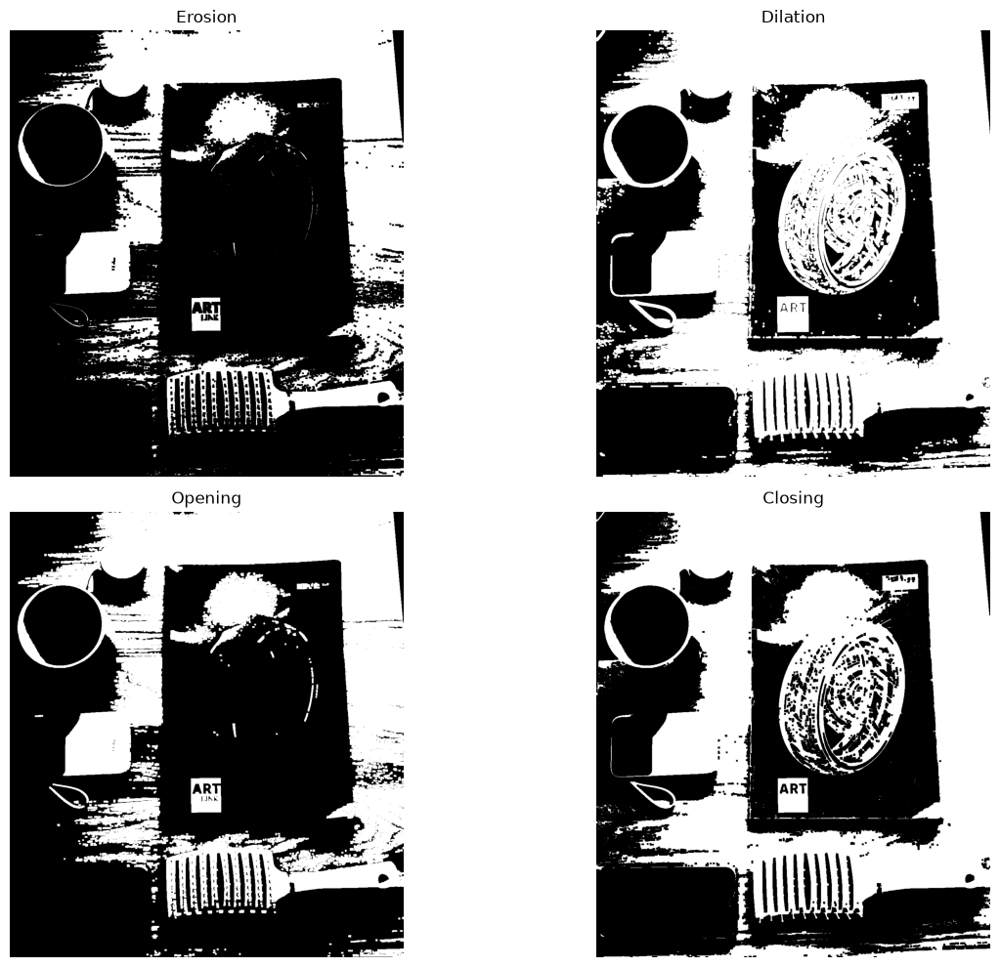

All four morphological outputs saved!


In [20]:
os.makedirs("outputs", exist_ok=True)

plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.imshow(erosion, cmap="gray")
plt.title("Erosion")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(dilation, cmap="gray")
plt.title("Dilation")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(opening, cmap="gray")
plt.title("Opening")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(closing, cmap="gray")
plt.title("Closing")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite("outputs/erosion.png", erosion)
cv2.imwrite("outputs/dilation.png", dilation)
cv2.imwrite("outputs/opening.png", opening)
cv2.imwrite("outputs/closing.png", closing)

print("All four morphological outputs saved!")


## Results and Observations

### 1. Noise Addition
Gaussian noise and salt-and-pepper noise were added to the original photograph. Gaussian noise introduced random intensity variations, while salt-and-pepper noise introduced black and white pixels.

### 2. Image Restoration
Gaussian filtering was applied to reduce Gaussian noise, while median filtering was used to reduce salt-and-pepper noise. The restored images were compared visually with the original photograph.

### 3. Image Quality Evaluation
PSNR and SSIM were calculated to evaluate the restored images. PSNR measures the difference between the original and restored images, while SSIM compares their structural similarity. Higher values generally indicate better restoration quality.

### 4. Image Thresholding
Binary thresholding and Otsu thresholding were used to separate image regions based on pixel intensity.

### 5. Morphological Operations
Erosion, dilation, opening, and closing were applied to the thresholded image. These operations changed the size and structure of foreground regions and helped remove small noise or fill small gaps.

### 6. Canny Edge Detection
Canny edge detection was used to identify boundaries and edges in the photograph.

### 7. Watershed Segmentation
Watershed segmentation was applied to identify and separate image regions using marker-based segmentation.

## Conclusion
This task demonstrated several fundamental computer vision techniques for image restoration and segmentation. Gaussian and median filtering were used to reduce different types of noise, while PSNR and SSIM provided quantitative measures of restoration quality. Thresholding and morphological operations helped process foreground regions, Canny detected edges, and watershed was used to segment image regions. The experiment showed how different techniques can be selected depending on the type of noise and the segmentation objective.
